In [ ]:
!pip install optuna

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 442.4/442.4 kB 8.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 268.7/268.7 kB 8.7 MB/s eta 0:00:00


# Vanishing Gradient trong Vanilla RNN, LSTM và GRU

## Bài toán: Ghi nhớ phần tử đầu tiên

Mỗi chuỗi dài $T$ bước. Chỉ bước đầu tiên chứa thông tin: $x_0 \sim \mathcal{U}[-1, 1]$; mọi bước còn lại bằng 0. Model đọc hết chuỗi rồi phải dự đoán lại $x_0$ ở bước cuối.

Bài toán được chọn vì nó **cô lập đúng một khả năng**: giữ thông tin qua $T$ bước. Muốn học được, gradient của loss phải lan ngược đủ $T-1$ bước để về tới $t = 0$. Đây chính là chỗ vanishing gradient phát huy tác dụng.

**Memoryless baseline:** một model không nhớ gì chỉ có thể đoán giá trị trung bình 0, cho MSE bằng phương sai của $\mathcal{U}[-1,1]$:

$$\text{MSE}_{\text{baseline}} = \frac{(1-(-1))^2}{12} = \frac{1}{3} \approx 0.333$$

Model kẹt quanh 0.333 nghĩa là **không học được gì**.

## Câu hỏi nghiên cứu

1. Vanilla RNN, LSTM và GRU khác nhau thế nào khi $T$ tăng (10, 30, 100)?
2. Khác biệt đó có phải do vanishing gradient không? Đo trực tiếp $\|\frac{\partial L}{\partial h_t}\|$ theo từng bước thời gian.
3. Cách khởi tạo bias của cổng Forget Gate trong LSTM và Reset Gate trong GRU có ảnh hưởng nhiều đến mô hình hay không

## Nguyên tắc đánh giá

- Mọi model có **cùng không gian tìm kiếm và cùng ngân sách** Optuna (20 trial). Bias của cổng **không** được tune, mà được nghiên cứu riêng trong ablation.
- Tune trên **tập validation cố định**, báo cáo cuối cùng trên **tập test cố định** chưa từng dùng khi chọn tham số.
- Mỗi cấu hình chạy **5 seed**, báo cáo **mean ± std**.
- Báo cáo song song cấu hình **mặc định** và **sau tuning**; chênh lệch giữa hai cấu hình cho biết độ nhạy với siêu tham số.

## Cấu trúc notebook

| Phần | Cell | Nội dung |
|---|---|---|
| Chuẩn bị | 1–6 | Thiết lập, cấu hình, dữ liệu, model, khởi tạo, vòng huấn luyện |
| Thí nghiệm chính | 7–10 | Optuna, huấn luyện nhiều seed, bảng tổng hợp, learning curve |
| Phân tích gradient | 11–12 | Gradient lúc khởi tạo (có kiểm soát), heatmap trong lúc huấn luyện |
| Ablation bias | 13–14 | zero / one / chrono; quét bias liên tục |



## 1. Thiết lập môi trường và tính tái hiện

In [ ]:
# Cell 1: Thiết lập
import os
os.environ["CUBLAS_WORKSPACE_CONFIG"] = ":4096:8"   # bắt buộc cho use_deterministic_algorithms trên GPU

import random
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
import torch.nn.functional as F
import torch.optim as optim
import matplotlib.pyplot as plt
import seaborn as sns
import optuna
from optuna.samplers import TPESampler
from optuna.pruners import MedianPruner

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
torch.use_deterministic_algorithms(True)
print(f"Device: {device}")


def set_seed(seed):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)   # seed cả CPU lẫn mọi GPU

Device: cpu


## 2. Cấu hình thí nghiệm

Các siêu tham số được thiết lập như sau:

| Biến | Giá trị | Ý nghĩa |
|---|---|---|
| `SEQ_LENS` | 10, 30, 100 | Độ dài chuỗi được thử |
| `SEEDS` | 0–4 | Seed cho các lần chạy cuối; báo cáo mean ± std trên 5 seed |
| `EPOCHS` / `TUNE_EPOCHS` | 300 / 150 | Số bước cập nhật khi huấn luyện cuối / khi tuning |
| `N_TRIALS` | 20 | Ngân sách Optuna, **giống nhau cho cả 3 model** |
| `EVAL_EVERY` | 10 | Đánh giá trên validation mỗi 10 bước |
| `N_EVAL` | 2048 | Kích thước tập validation và tập test |
| `TUNE_SEED_OFFSET` | 1000 | Seed của các trial Optuna, tách biệt với `SEEDS` để tránh *selection bias* |


In [ ]:
# Cell 2: Cấu hình thí nghiệm
SEQ_LENS     = [10, 30, 100]
MODEL_NAMES  = ['Vanilla RNN', 'LSTM', 'GRU']
SEEDS        = [0, 1, 2, 3, 4]      # seed cho các lần chạy cuối (báo cáo mean ± std)

EPOCHS       = 300                  # huấn luyện cuối
TUNE_EPOCHS  = 150                  # huấn luyện ngắn trong Optuna
N_TRIALS     = 20                   # cùng ngân sách cho cả 3 model
BATCH_SIZE   = 128
EVAL_EVERY   = 10                   # đánh giá trên validation mỗi 10 epoch
N_EVAL       = 2048                 # kích thước tập val / test

VAL_SEED, TEST_SEED = 10_000, 20_000
TUNE_SEED_OFFSET    = 1_000         # seed của các trial Optuna, tách biệt với SEEDS

# Cấu hình "mặc định" (không tune) — giống nhau cho cả 3 model
DEFAULT_CONFIG = {"lr": 1e-3, "hidden_size": 32, "init_method": "default"}

# Cách khởi tạo bias cổng dùng trong thí nghiệm chính (cả default lẫn tuned).
MAIN_GATE_INIT = "one"

## 3. Dữ liệu

**`generate_memorization_task(batch_size, seq_len)`** sinh một batch:
- `X` có shape `(seq_len, batch_size, 1)`: toàn số 0, trừ bước $t = 0$ được gán giá trị ngẫu nhiên trong $[-1, 1]$.
- `Y` có shape `(batch_size, 1)`: chính là `X[0]`, giá trị model cần nhớ.


In [ ]:
def generate_memorization_task(batch_size, seq_len, generator=None):
    """
    X shape: (seq_len, batch_size, 1) — chỉ bước t=0 khác 0, giá trị ~ U[-1, 1]
    Y shape: (batch_size, 1)          — chính là X tại t=0
    """
    X = torch.zeros(seq_len, batch_size, 1)
    X[0, :, 0] = torch.rand(batch_size, generator=generator) * 2 - 1
    Y = X[0].clone()
    return X.to(device), Y.to(device)


def make_fixed_set(n, seq_len, seed):
    """Tập cố định, sinh bằng generator riêng nên không ảnh hưởng RNG của quá trình huấn luyện."""
    g = torch.Generator().manual_seed(seed)
    return generate_memorization_task(n, seq_len, generator=g)


_EVAL_SETS = {}
def get_eval_sets(T):
    if T not in _EVAL_SETS:
        _EVAL_SETS[T] = {"val":  make_fixed_set(N_EVAL, T, VAL_SEED),
                         "test": make_fixed_set(N_EVAL, T, TEST_SEED)}
    return _EVAL_SETS[T]


# Memoryless baseline = phương sai của U[-1, 1]
MEMORYLESS_BASELINE = (1 - (-1)) ** 2 / 12
print(f"Memoryless Baseline MSE: {MEMORYLESS_BASELINE:.4f}")

Memoryless Baseline MSE: 0.3333


## 4. Xây dựng các model

Cả ba model được tự cài đặt lại từ đầu để có thể đọc gradient tại từng bước thời gian. Mỗi model đọc chuỗi từng bước, rồi dự đoán từ trạng thái ẩn cuối cùng $h_{T-1}$.

**Vanilla RNN**
$$h_t = \tanh(W_{ih}\, x_t + W_{hh}\, h_{t-1} + b)$$

**LSTM**:
$$i, f, o = \sigma(\cdot), \quad \tilde c_t = \tanh(\cdot), \quad c_t = \mathbf{f} \odot c_{t-1} + i \odot \tilde c_t, \quad h_t = o \odot \tanh(c_t)$$

**GRU**:
$$h_t = (1 - \mathbf{z}) \odot h_{t-1} + z \odot \tilde h_t$$

**Lưu ý:** Quy ước GRU ở đây **ngược với `nn.GRU`** của PyTorch (PyTorch dùng $h_t = (1-z)\odot \tilde h_t + z \odot h_{t-1}$). Muốn giữ trạng thái cũ, ở đây cần $z \to 0$, tức **bias âm**.

**Theo dõi gradient:**
- `_track(h)` gọi `h.retain_grad()` để PyTorch giữ lại $\partial L/\partial h_t$, vốn bị bỏ đi sau `backward()` vì $h_t$ là tensor trung gian.
- `get_gradient_norms()` trả về $\|\partial L/\partial h_t\|_2$, lấy trung bình trên batch, cho $t = 0, \dots, T-1$.


In [ ]:
class TrackerBase(nn.Module):
    """Phần dùng chung: lưu h_t và đọc ||dL/dh_t||."""

    def _track(self, h):
        if h.requires_grad:          # dưới torch.no_grad() (lúc evaluate) thì bỏ qua
            h.retain_grad()
        self.h_states.append(h)

    def get_gradient_norms(self):
        """||dL/dh_t||_2 trung bình trên batch, từ t=0 đến t=T-1."""
        return [h.grad.norm(p=2, dim=1).mean().item() if h.grad is not None else 0.0
                for h in self.h_states]


class VanillaRNN_Tracker(TrackerBase):
    def __init__(self, input_size, hidden_size, output_size):
        super().__init__()
        self.hidden_size = hidden_size
        self.W_ih = nn.Linear(input_size, hidden_size)
        self.W_hh = nn.Linear(hidden_size, hidden_size, bias=False)
        self.W_ho = nn.Linear(hidden_size, output_size)
        self.h_states = []

    def forward(self, x):
        seq_len, batch_size, _ = x.size()
        h = torch.zeros(batch_size, self.hidden_size, dtype=x.dtype, device=x.device)
        self.h_states = []
        for t in range(seq_len):
            h = torch.tanh(self.W_ih(x[t]) + self.W_hh(h))
            self._track(h)
        return self.W_ho(h)


class LSTM_Tracker(TrackerBase):
    def __init__(self, input_size, hidden_size, output_size):
        super().__init__()
        self.hidden_size = hidden_size
        combined_size = input_size + hidden_size
        self.W_i = nn.Linear(combined_size, hidden_size)   # Input gate
        self.W_f = nn.Linear(combined_size, hidden_size)   # Forget gate
        self.W_c = nn.Linear(combined_size, hidden_size)   # Candidate
        self.W_o = nn.Linear(combined_size, hidden_size)   # Output gate
        self.W_out = nn.Linear(hidden_size, output_size)
        self.h_states, self.c_states = [], []

    def forward(self, x):
        seq_len, batch_size, _ = x.size()
        h = torch.zeros(batch_size, self.hidden_size, dtype=x.dtype, device=x.device)
        c = torch.zeros(batch_size, self.hidden_size, dtype=x.dtype, device=x.device)
        self.h_states, self.c_states = [], []
        for t in range(seq_len):
            combined = torch.cat((x[t], h), dim=1)
            i = torch.sigmoid(self.W_i(combined))
            f = torch.sigmoid(self.W_f(combined))
            c_tilde = torch.tanh(self.W_c(combined))
            o = torch.sigmoid(self.W_o(combined))
            c = f * c + i * c_tilde
            h = o * torch.tanh(c)
            self._track(h)
            self.c_states.append(c.detach())   # để phân tích trạng thái cell nếu cần
        return self.W_out(h)


class GRU_Tracker(TrackerBase):
    def __init__(self, input_size, hidden_size, output_size):
        super().__init__()
        self.hidden_size = hidden_size
        combined_size = input_size + hidden_size
        self.W_z = nn.Linear(combined_size, hidden_size)   # Update gate
        self.W_r = nn.Linear(combined_size, hidden_size)   # Reset gate
        self.W_h = nn.Linear(combined_size, hidden_size)   # Candidate
        self.W_out = nn.Linear(hidden_size, output_size)
        # KHÔNG gán bias cứng ở đây — xem apply_gate_init
        self.h_states = []

    def forward(self, x):
        seq_len, batch_size, _ = x.size()
        h = torch.zeros(batch_size, self.hidden_size, dtype=x.dtype, device=x.device)
        self.h_states = []
        for t in range(seq_len):
            combined = torch.cat((x[t], h), dim=1)
            z = torch.sigmoid(self.W_z(combined))
            r = torch.sigmoid(self.W_r(combined))
            h_tilde = torch.tanh(self.W_h(torch.cat((x[t], r * h), dim=1)))
            h = (1 - z) * h + z * h_tilde
            self._track(h)
        return self.W_out(h)


MODEL_CLASSES = {'Vanilla RNN': VanillaRNN_Tracker, 'LSTM': LSTM_Tracker, 'GRU': GRU_Tracker}

## 5. Khởi tạo trọng số và bias của cổng

**`apply_weight_init(model, init_method)`** khởi tạo lại các ma trận trọng số theo `orthogonal`, `xavier`, hoặc giữ mặc định của `nn.Linear`. Hàm này không khởi tạo bias.

**`apply_gate_init(model, mode, T)`** đặt bias cho cổng "giữ trạng thái cũ". Mọi giá trị $b$ được hiểu theo **hướng giữ lại**, nên LSTM và GRU so sánh được với nhau:

| Model | Bias thực tế | Hệ số giữ |
|---|---|---|
| LSTM | $b_f = b$ | $f = \sigma(b)$ |
| GRU | $b_z = -b$ (đổi dấu vì quy ước $h = (1-z)h + z\tilde h$) | $1 - z = \sigma(b)$ |

Các chế độ:

| `mode` | $b$ | Hệ số giữ ban đầu |
|---|---|---|
| `"default"` | không can thiệp (giá trị ngẫu nhiên nhỏ của `nn.Linear`) | ≈ 0.5 |
| `"zero"` | 0 | 0.5 |
| `"one"` | 1 | ≈ 0.73 |
| `"chrono"` | $\log(\tau)$, $\tau \sim \mathcal{U}[1, T-1]$, khác nhau cho từng unit | từ 0.5 đến ≈ 0.99 |
| số thực | giá trị đó | $\sigma(b)$ |

**Chrono initialization** (Tallec & Ollivier, 2018). Một unit có hệ số giữ $f$ thì nhớ được khoảng $1/(1-f)$ bước. Đặt $b = \log\tau$ thì $f = \tau/(1+\tau)$, suy ra tầm nhớ ≈ $1 + \tau$ bước. Chrono rải đều tầm nhớ của các unit trong khoảng từ vài bước đến $T$ bước. Với LSTM, chrono còn đặt $b_i = -b_f$: unit nào giữ lâu thì ghi thông tin mới ít đi.

In [ ]:
# Cell 5 — Khởi tạo trọng số và bias cổng
def apply_weight_init(model, init_method):
    for name, p in model.named_parameters():
        if 'weight' in name and p.dim() >= 2:
            if init_method == "orthogonal":
                nn.init.orthogonal_(p)
            elif init_method == "xavier":
                nn.init.xavier_uniform_(p)
            # "default": giữ khởi tạo của nn.Linear


def apply_gate_init(model, mode, T):
    """
    Khởi tạo bias của cổng "giữ trạng thái cũ".
    mode: "default" (không can thiệp), "zero", "one", "chrono", hoặc một số thực b.

    Mọi giá trị b được hiểu theo HƯỚNG GIỮ LẠI, để LSTM và GRU so sánh được:
      - LSTM: b_f = b               → hệ số giữ f      = sigmoid(b)
      - GRU : b_z = -b              → hệ số giữ (1 - z) = sigmoid(b)
    Chrono (Tallec & Ollivier, 2018): b ~ log U(1, T_max - 1); với LSTM thêm b_i = -b_f.
    Lưu ý: model tự cài đặt nên mỗi cổng chỉ có MỘT bias (khác nn.LSTM có bias_ih + bias_hh).
    """
    if mode == "default" or isinstance(model, VanillaRNN_Tracker):
        return
    H = model.hidden_size
    if isinstance(mode, (int, float)):
        b = torch.full((H,), float(mode))
    elif mode == "zero":
        b = torch.zeros(H)
    elif mode == "one":
        b = torch.ones(H)
    elif mode == "chrono":
        b = torch.log(torch.empty(H).uniform_(1, max(T - 1, 2)))
    else:
        raise ValueError(f"gate init không hợp lệ: {mode}")

    with torch.no_grad():
        if isinstance(model, LSTM_Tracker):
            model.W_f.bias.copy_(b)
            if mode == "chrono":
                model.W_i.bias.copy_(-b)
        elif isinstance(model, GRU_Tracker):
            model.W_z.bias.copy_(-b)        # đổi dấu vì quy ước h = (1-z)h + z*h_tilde


def build_model(name, config, gate_init, T, dtype=torch.float32):
    model = MODEL_CLASSES[name](1, config["hidden_size"], 1)
    apply_weight_init(model, config["init_method"])
    apply_gate_init(model, gate_init, T)
    return model.to(device=device, dtype=dtype)

## 6. Huấn luyện và đánh giá

In [ ]:
# Cell 6 — Huấn luyện và đánh giá
@torch.no_grad()
def evaluate(model, X, Y):
    model.eval()
    loss = F.mse_loss(model(X), Y).item()
    model.train()
    return loss


def train_model(name, config, T, seed, epochs, gate_init=MAIN_GATE_INIT,
                record_grad_epochs=(), trial=None):
    """
    Huấn luyện 1 model. Dữ liệu train sinh mới mỗi epoch; validation là tập cố định.
    Nếu truyền `trial`, val loss được báo cho Optuna để pruning.
    """
    set_seed(seed)
    model = build_model(name, config, gate_init, T)
    optimizer = optim.Adam(model.parameters(), lr=config["lr"])
    X_val, Y_val = get_eval_sets(T)["val"]

    hist = {"train_loss": [], "val_epochs": [], "val_loss": [], "grad_norms": {}}
    for epoch in range(epochs):
        optimizer.zero_grad()
        X, Y = generate_memorization_task(BATCH_SIZE, T)
        loss = F.mse_loss(model(X), Y)
        loss.backward()

        if epoch in record_grad_epochs:
            hist["grad_norms"][epoch] = model.get_gradient_norms()

        torch.nn.utils.clip_grad_norm_(model.parameters(), max_norm=5.0)
        optimizer.step()
        hist["train_loss"].append(loss.item())

        if (epoch + 1) % EVAL_EVERY == 0 or epoch == epochs - 1:
            v = evaluate(model, X_val, Y_val)
            hist["val_epochs"].append(epoch + 1)
            hist["val_loss"].append(v)
            if trial is not None:
                trial.report(v, epoch + 1)
                if trial.should_prune():
                    raise optuna.exceptions.TrialPruned()

    hist["final_val"] = hist["val_loss"][-1]
    return model, hist

## 7. Tìm siêu tham số bằng Optuna

Dùng Optuna để tìm cấu hình tốt nhất cho một model ở một độ dài $T$.

**Không gian tìm kiếm, giống nhau cho cả 3 model:**

| Tham số | Miền giá trị |
|---|---|
| `lr` | $[10^{-4},\ 5\cdot10^{-2}]$, lấy mẫu đều theo **thang log** |
| `hidden_size` | 16, 32, 64 |
| `init_method` | orthogonal, xavier, default |



In [ ]:
# Cell 7 — Optuna (chỉ tune tham số chung, trên validation)
def tune_model(name, T, n_trials=N_TRIALS):
    def objective(trial):
        config = {
            "lr": trial.suggest_float("lr", 1e-4, 5e-2, log=True),
            "hidden_size": trial.suggest_categorical("hidden_size", [16, 32, 64]),
            "init_method": trial.suggest_categorical("init_method", ["orthogonal", "xavier", "default"]),
        }
        _, hist = train_model(name, config, T, seed=TUNE_SEED_OFFSET + trial.number,
                              epochs=TUNE_EPOCHS, trial=trial)
        return hist["final_val"]

    optuna.logging.set_verbosity(optuna.logging.WARNING)
    study = optuna.create_study(
        direction="minimize",
        sampler=TPESampler(seed=42),
        # warm-up 50 epoch: tránh cắt sớm các model khởi đầu chậm (thường nằm ở baseline vài chục epoch đầu)
        pruner=MedianPruner(n_startup_trials=5, n_warmup_steps=50),
    )
    study.optimize(objective, n_trials=n_trials)
    print(f"  [{name}] best val MSE = {study.best_value:.4f} | params = {study.best_params}")
    return study.best_params

## 8. Bắt đầu chạy thí nghiệm

Với mỗi $T \in \{10, 30, 100\}$ và mỗi model:

1. **Tune** bằng Optuna (Cell 7), thu được `best_params[T][model]`.
2. Huấn luyện **hai cấu hình** (`default` và `tuned`), mỗi cấu hình **5 seed**, mỗi lần 300 bước.
3. Đánh giá model ở trạng thái cuối trên **tập test**.


In [ ]:
# Cell 8 — Thí nghiệm chính: tune → chạy lại nhiều seed (default & tuned) → đo trên test
RECORD_GRAD_EPOCHS = (0, 50, 150, EPOCHS - 1)

results, best_params = {}, {}
for T in SEQ_LENS:
    print("\n" + "=" * 60 + f"\nSEQUENCE LENGTH T = {T}\n" + "=" * 60)
    results[T], best_params[T] = {}, {}
    X_te, Y_te = get_eval_sets(T)["test"]

    for name in MODEL_NAMES:
        best_params[T][name] = tune_model(name, T)
        results[T][name] = {}
        for setting, config in [("default", DEFAULT_CONFIG), ("tuned", best_params[T][name])]:
            runs = []
            for seed in SEEDS:
                model, hist = train_model(name, config, T, seed, EPOCHS,
                                          record_grad_epochs=RECORD_GRAD_EPOCHS)
                runs.append({"seed": seed, "hist": hist, "test_mse": evaluate(model, X_te, Y_te)})
            results[T][name][setting] = runs
            tests = [r["test_mse"] for r in runs]
            print(f"  [{name} | {setting:7s}] test MSE = {np.mean(tests):.4f} ± {np.std(tests, ddof=1):.4f}")


SEQUENCE LENGTH T = 10
  [Vanilla RNN] best val MSE = 0.0000 | params = {'lr': 0.025427119762938283, 'hidden_size': 64, 'init_method': 'default'}
  [Vanilla RNN | default] test MSE = 0.0003 ± 0.0003
  [Vanilla RNN | tuned  ] test MSE = 0.1163 ± 0.1391
  [LSTM] best val MSE = 0.0000 | params = {'lr': 0.03398306658839224, 'hidden_size': 32, 'init_method': 'xavier'}
  [LSTM | default] test MSE = 0.0008 ± 0.0001
  [LSTM | tuned  ] test MSE = 0.0000 ± 0.0000
  [GRU] best val MSE = 0.0000 | params = {'lr': 0.04811786734282387, 'hidden_size': 16, 'init_method': 'xavier'}
  [GRU | default] test MSE = 0.0001 ± 0.0000
  [GRU | tuned  ] test MSE = 0.0000 ± 0.0000

SEQUENCE LENGTH T = 30
  [Vanilla RNN] best val MSE = 0.0009 | params = {'lr': 0.0028382428109487165, 'hidden_size': 32, 'init_method': 'orthogonal'}
  [Vanilla RNN | default] test MSE = 0.3409 ± 0.0004
  [Vanilla RNN | tuned  ] test MSE = 0.0020 ± 0.0023
  [LSTM] best val MSE = 0.0000 | params = {'lr': 0.01631726750125843, 'hidden_siz

## 9. Bảng tổng hợp: mặc định và sau tuning

Bảng tổng hợp kết quả chạy của 3 mô hình với 3 giá trị $T$ khác nhau.

Chúng ta có thể đánh giá sơ bộ kết quả của các mô hình như sau:
- Với Vanilla RNN, khi độ dài chuỗi lớn, mô hình gần như quên toàn bộ thông tin ở đầu chuỗi, dẫn đến giá trị Test MSE xấp xỉ giá trị baseline. Tại $T = 100$ kể cả khi dùng Optuna để tìm siêu tham số tối ưu, mô hình vẫn không nhớ được giá trị ở quá xa.
- LSTM và GRU có thể nhớ được khi $T = 30$. Tuy nhiên, khi T lớn ($T = 100$), 2 mô hình này cũng cho ra kết quả tương tự Vanilla RNN. Riêng LSTM thì có thể nhớ được khi đã tuning tham số.

Như vậy, có thể không như lý thuyết, việc dùng LSTM hay GRU vẫn chưa đảm bảo được việc mô hình sẽ giải quyết được **Gradient Vanishing**.

Sau khi tìm hiểu, nhóm đã xem xét đến cách khởi tạo của bias trong **Forget Gate** trong LSTM hay **Reset Gate** trong GRU.

In [ ]:
# Cell 9 — Bảng tổng hợp: mặc định vs sau tuning
def mean_std(xs, fmt=".4f"):
    xs = np.asarray(xs, dtype=float)
    return f"{xs.mean():{fmt}} ± {xs.std(ddof=1):{fmt}}"

rows = []
for T in SEQ_LENS:
    for name in MODEL_NAMES:
        d = [r["test_mse"] for r in results[T][name]["default"]]
        t = [r["test_mse"] for r in results[T][name]["tuned"]]
        rows.append({
            "T": T, "Model": name,
            "Test MSE (mặc định)": mean_std(d),
            "Test MSE (sau tuning)": mean_std(t),
            "Chênh lệch (mặc định − tuned)": f"{np.mean(d) - np.mean(t):+.4f}",
            "Tham số tuned": best_params[T][name],
        })
summary = pd.DataFrame(rows)
display(summary)

,T,Model,Test MSE (mặc định),Test MSE (sau tuning),Chênh lệch (mặc định − tuned),Tham số tuned
0,10,Vanilla RNN,0.0003 ± 0.0003,0.1163 ± 0.1391,-0.1160,"{'lr': 0.025427119762938283, 'hidden_size': 64..."
1,10,LSTM,0.0008 ± 0.0001,0.0000 ± 0.0000,+0.0008,"{'lr': 0.03398306658839224, 'hidden_size': 32,..."
2,10,GRU,0.0001 ± 0.0000,0.0000 ± 0.0000,+0.0001,"{'lr': 0.04811786734282387, 'hidden_size': 16,..."
3,30,Vanilla RNN,0.3409 ± 0.0004,0.0020 ± 0.0023,+0.3389,"{'lr': 0.0028382428109487165, 'hidden_size': 3..."
4,30,LSTM,0.0002 ± 0.0001,0.0686 ± 0.1523,-0.0684,"{'lr': 0.01631726750125843, 'hidden_size': 64,..."
5,30,GRU,0.0011 ± 0.0001,0.0000 ± 0.0000,+0.0011,"{'lr': 0.014124797687456494, 'hidden_size': 64..."
6,100,Vanilla RNN,0.3409 ± 0.0004,0.3410 ± 0.0005,-0.0002,"{'lr': 0.00030955664602423704, 'hidden_size': ..."
7,100,LSTM,0.3409 ± 0.0002,0.0002 ± 0.0003,+0.3407,"{'lr': 0.0005987426889485295, 'hidden_size': 6..."
8,100,GRU,0.3409 ± 0.0002,0.3408 ± 0.0000,+0.0001,"{'lr': 0.00018599908887563567, 'hidden_size': ..."


## 10. Learning curves

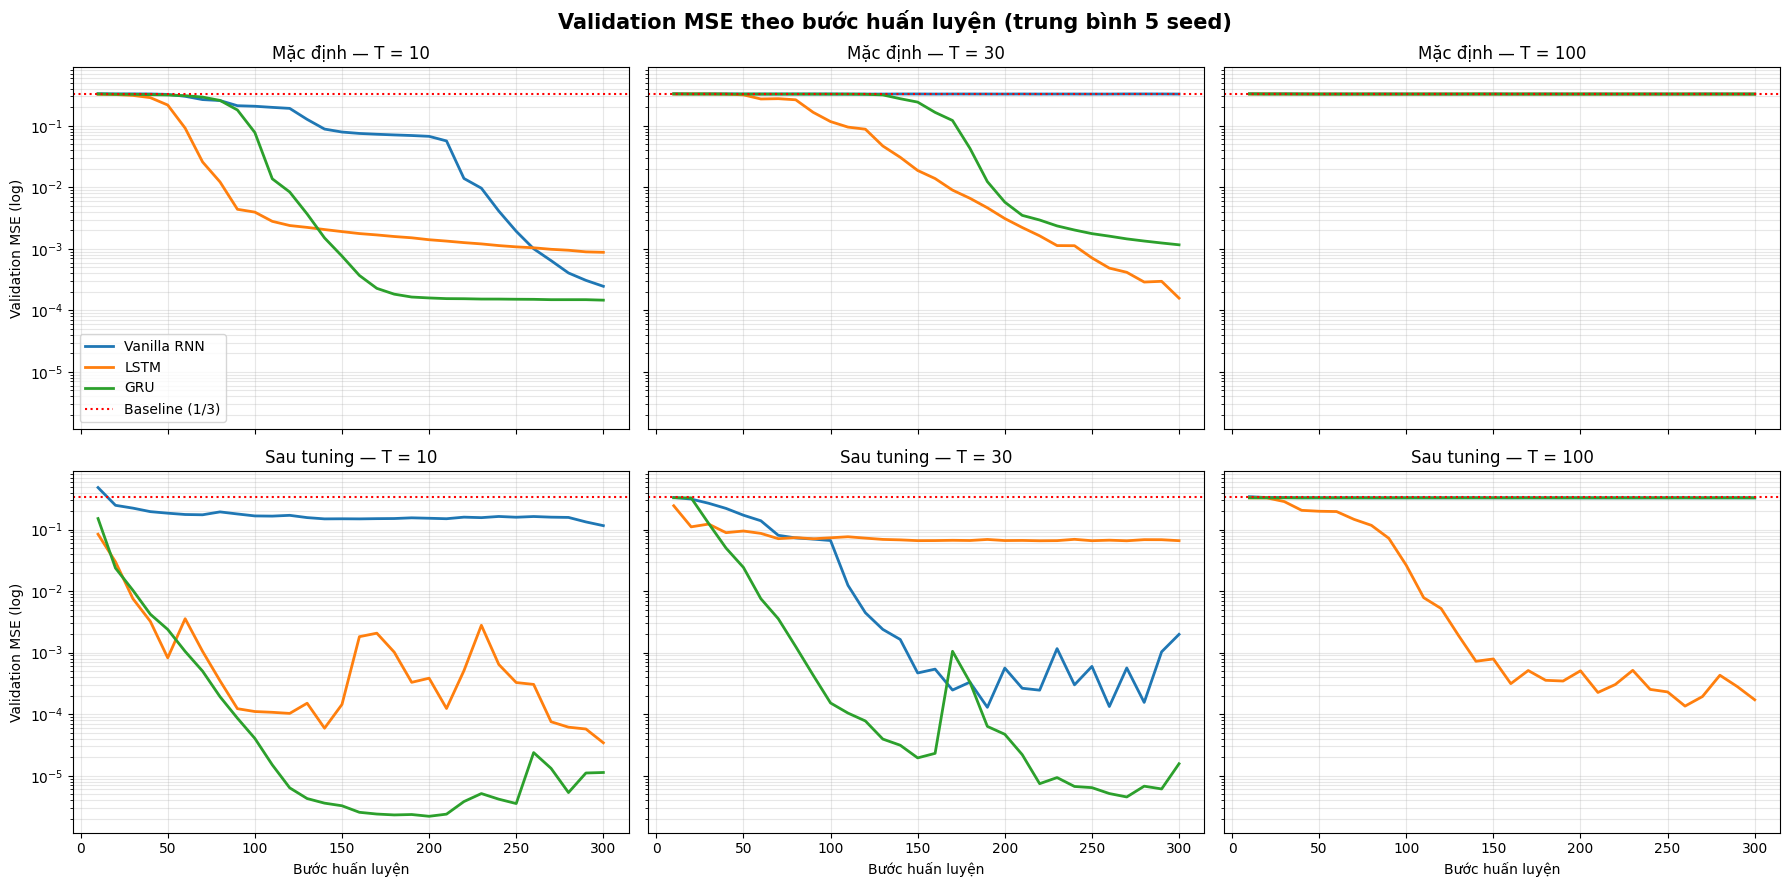

In [ ]:
# Cell 10 — Learning curves (val loss, mean ± std trên các seed)
colors = dict(zip(MODEL_NAMES, ['C0', 'C1', 'C2']))
SETTINGS = [("default", "Mặc định"), ("tuned", "Sau tuning")]

fig, axes = plt.subplots(len(SETTINGS), len(SEQ_LENS), figsize=(18, 9),
                         sharex=True, sharey=True)
fig.suptitle(f"Validation MSE theo bước huấn luyện (trung bình {len(SEEDS)} seed)",
             fontsize=15, fontweight='bold')

for row, (setting, setting_label) in enumerate(SETTINGS):
    for col, T in enumerate(SEQ_LENS):
        ax = axes[row, col]
        for name in MODEL_NAMES:
            runs = results[T][name][setting]
            x = runs[0]["hist"]["val_epochs"]
            V = np.array([r["hist"]["val_loss"] for r in runs])
            ax.plot(x, V.mean(0), color=colors[name], linewidth=2, label=name)
        ax.axhline(MEMORYLESS_BASELINE, color='r', linestyle=':', label='Baseline (1/3)')
        ax.set_yscale('log')
        ax.set_title(f"{setting_label} — T = {T}")
        ax.grid(True, which='both', alpha=0.3)
        if row == len(SETTINGS) - 1:
            ax.set_xlabel("Bước huấn luyện")
        if col == 0:
            ax.set_ylabel("Validation MSE (log)")

axes[0, 0].legend()
plt.tight_layout()
plt.show()

## 11. So sánh Gradient lúc khởi tạo

Ta so sánh Gradient tương đối của các mô hình lúc mô hình được khởi tạo:
$$\frac{\|\partial L/\partial h_t\|}{\|\partial L/\partial h_{T-1}\|}$$
tức phần tín hiệu lỗi còn lại sau khi lan ngược từ bước cuối về bước $t$. Chuẩn hóa theo bước cuối để loại bỏ khác biệt về độ lớn tuyệt đối giữa các model.

**Hệ số suy giảm $r$:** mỗi bước lan ngược, gradient bị nhân với một hệ số gần như không đổi:
$$\|\partial L/\partial h_t\| \approx r \cdot \|\partial L/\partial h_{t+1}\|$$
Trên thang log, quan hệ này là một đường thẳng. `decay_factor_from_curves` khớp đường thẳng trên nửa sau chuỗi (bỏ bước cuối và giai đoạn quá độ ở đầu chuỗi), rồi tính $r = e^{-\text{độ dốc}}$.

| $r$ | Còn lại sau 99 bước ($r^{99}$) | Tầm nhớ ≈ $1/(1-r)$ |
|---|---|---|
| 0.45 | ≈ $10^{-34}$ | ≈ 2 bước |
| 0.80 | ≈ $10^{-10}$ | ≈ 5 bước |
| 0.97 | ≈ 0.05 | ≈ 33 bước |

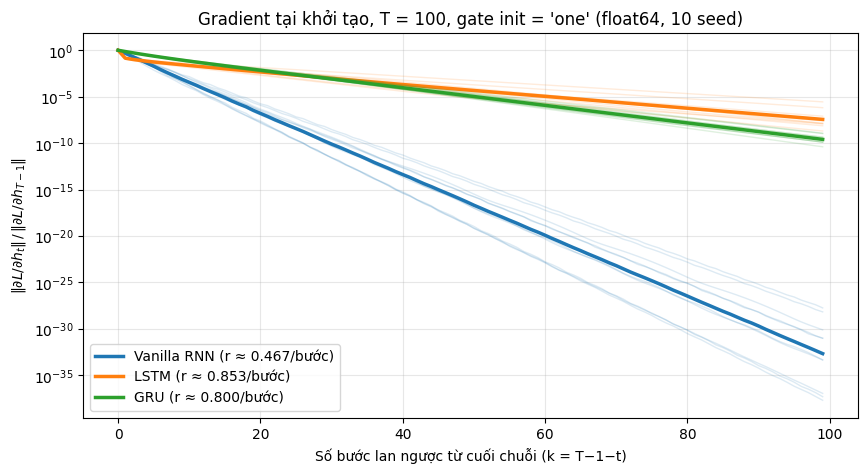

In [ ]:
# Cell 11 — Gradient flow tại khởi tạo (float64, cấu hình mặc định)
def measure_init_gradients(name, T, config=DEFAULT_CONFIG, gate_init=MAIN_GATE_INIT, n_seeds=10):
    """Trả về (đường trung bình hình học, ma trận từng seed) của ||dL/dh_t|| / ||dL/dh_{T-1}||."""
    curves = []
    for s in range(n_seeds):
        set_seed(s)
        model = build_model(name, config, gate_init, T, dtype=torch.float64)
        X, Y = generate_memorization_task(BATCH_SIZE, T)
        F.mse_loss(model(X.double()), Y.double()).backward()
        g = np.array(model.get_gradient_norms())
        curves.append(g / g[-1])
    curves = np.array(curves)
    if (curves == 0).any():
        print(f"[{name}] Cảnh báo: {(curves == 0).sum()} giá trị underflow về 0")
    mean_curve = np.exp(np.log(np.clip(curves, 1e-300, None)).mean(0))
    return mean_curve, curves


def decay_factor_from_curves(curves, T):
    """Hệ số r mỗi bước lan ngược (g_t = r * g_{t+1}), khớp trên nửa sau chuỗi, bỏ bước cuối."""
    t = np.arange(T // 2, T - 1)
    rates = [np.exp(-np.polyfit(t, np.log(np.clip(c[t], 1e-300, None)), 1)[0]) for c in curves]
    return np.mean(rates), np.std(rates, ddof=1)


T_GRAD = max(SEQ_LENS)
k = np.arange(T_GRAD)   # số bước lan ngược: k = T-1-t
plt.figure(figsize=(10, 5))
for name in MODEL_NAMES:
    mean_curve, seed_curves = measure_init_gradients(name, T_GRAD)
    r, r_std = decay_factor_from_curves(seed_curves, T_GRAD)
    for c in seed_curves:
        plt.semilogy(k, c[::-1], color=colors[name], alpha=0.15, linewidth=1)
    plt.semilogy(k, mean_curve[::-1], color=colors[name], linewidth=2.5,
                 label=f"{name} (r ≈ {r:.3f}/bước)")
plt.xlabel("Số bước lan ngược từ cuối chuỗi (k = T−1−t)")
plt.ylabel(r"$\|\partial L/\partial h_t\| \,/\, \|\partial L/\partial h_{T-1}\|$")
plt.title(f"Gradient tại khởi tạo, T = {T_GRAD}, gate init = '{MAIN_GATE_INIT}' (float64, 10 seed)")
plt.legend(); plt.grid(True, which='both', alpha=0.3)
plt.show()

## 12. Heatmap gradient trong quá trình huấn luyện

Có thể thấy rằng khi độ dài chuỗi lớn, Gradient của mô hình Vanilla RNN sẽ giảm rất nhanh khi truyền qua các bước thời gian t. Trong khi đó, LSTM vẫn giữ được gradient khi truyền qua các bước thời gian; ở các epoch sau, khi mô hình dần cập nhật, dải màu của LSTM ngày càng sáng hơn, chứng tỏ nó đã học được cách giữ lại thông tin ở bước đầu để dự đoán kết quả.

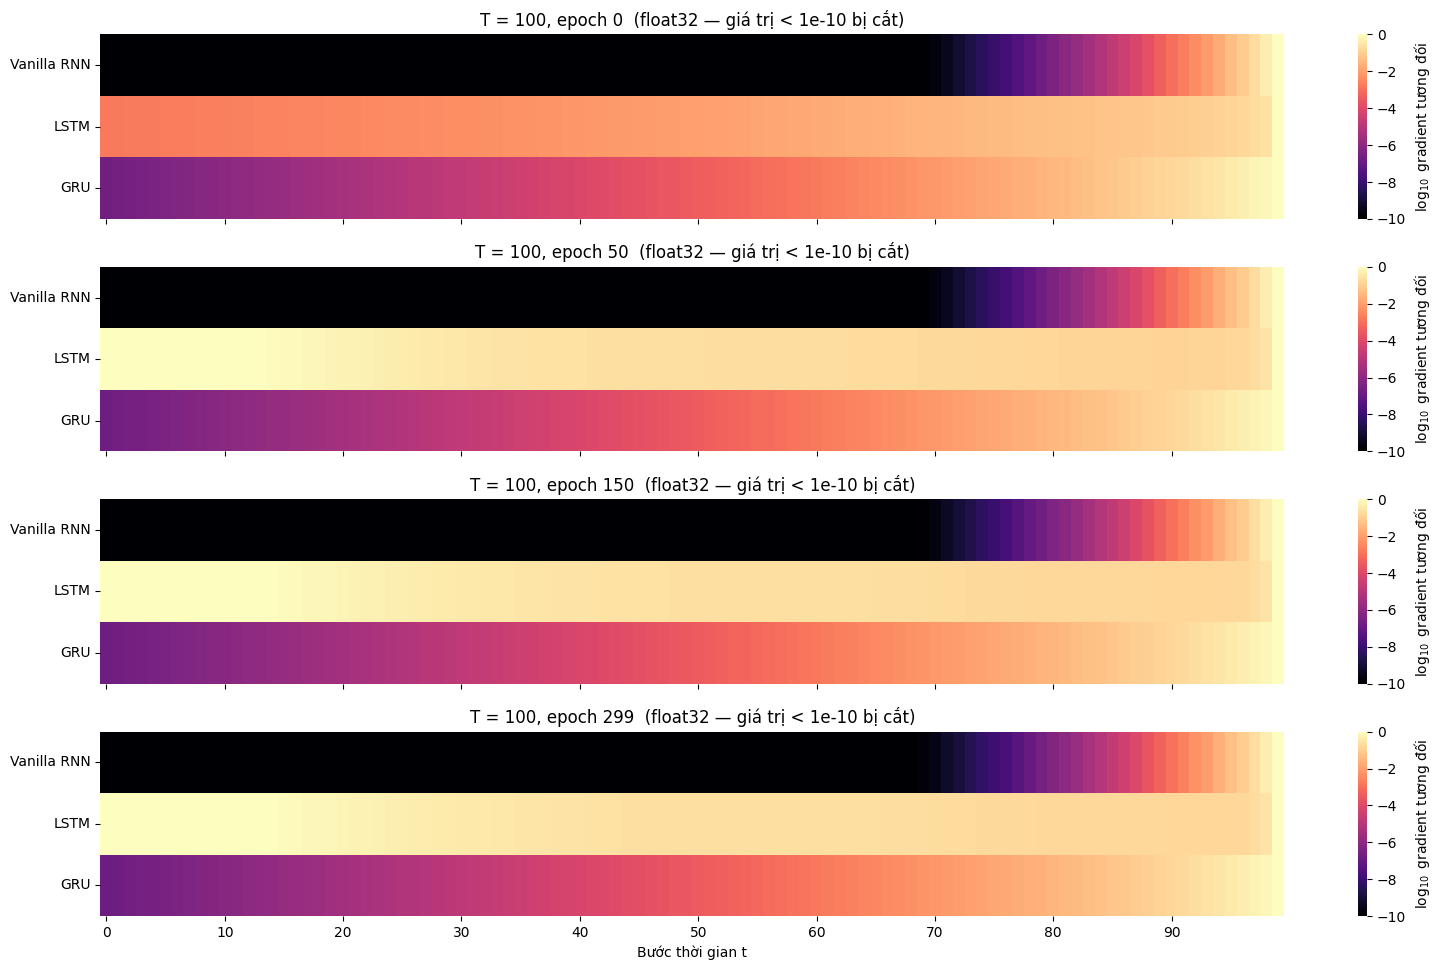

In [ ]:
# Cell 12 — Gradient flow heatmap trong quá trình huấn luyện (tuned, seed đầu tiên)
names = MODEL_NAMES
fig, axes = plt.subplots(len(RECORD_GRAD_EPOCHS), 1,
                         figsize=(16, 2.2 * len(RECORD_GRAD_EPOCHS) + 1), sharex=True)
for ax, ep in zip(axes, RECORD_GRAD_EPOCHS):
    M = np.array([results[T_GRAD][n]["tuned"][0]["hist"]["grad_norms"][ep] for n in names])
    M = np.log10(np.clip(M / (M[:, -1:] + 1e-30), 1e-10, None))
    sns.heatmap(M, ax=ax, cmap='magma', vmin=-10, vmax=0,
                yticklabels=names, xticklabels=max(T_GRAD // 10, 1),
                cbar_kws={'label': r'$\log_{10}$ gradient tương đối'})
    ax.set_yticklabels(names, rotation=0)
    ax.set_title(f"T = {T_GRAD}, epoch {ep}  (float32 — giá trị < 1e-10 bị cắt)")
axes[-1].set_xlabel("Bước thời gian t")
plt.tight_layout()
plt.show()

## 13. Ablation: bias khởi tạo của cổng

**Câu hỏi:** LSTM/GRU tốt hơn RNN là nhờ **kiến trúc có cổng**, hay nhờ **cách khởi tạo bias của cổng**?

**Thiết kế:** giữ nguyên mọi thứ, chỉ thay đổi bias cổng:

| Điều kiện | Hệ số giữ ban đầu |
|---|---|
| Vanilla RNN (mốc tham chiếu, không có cổng) | — |
| LSTM / GRU × **zero** | 0.5 |
| LSTM / GRU × **one** | ≈ 0.73 |
| LSTM / GRU × **chrono** | rải từ 0.5 đến ≈ 0.99 |

**Kết quả**: mô hình LSTM và GRU có thể học được và giải quyết được Gradient Vanishing khi $T = 100$ với khởi tạo `chrono`. Điều đó cho thấy bias initialization của các cổng này cũng đóng góp vào việc giúp mô hình giải quyết được **Gradient Vanishing** thay vì chỉ bản thân nmz




In [ ]:
# Cell 13 — Ablation bias của cổng: zero / one / chrono
ABLATION_T  = [100]            # thêm 10, 30 nếu còn thời gian
GATE_INITS  = ["zero", "one", "chrono"]
THRESHOLD   = 0.01             # "học được" = val MSE < 0.01


def epochs_to_threshold(hist, thr=THRESHOLD):
    for e, v in zip(hist["val_epochs"], hist["val_loss"]):
        if v < thr:
            return e
    return np.nan


def fmt_speed(speeds):
    speeds = np.asarray(speeds, dtype=float)
    ok = ~np.isnan(speeds)
    if not ok.any():
        return f"không đạt (0/{len(speeds)})"
    return f"{speeds[ok].mean():.0f} ({ok.sum()}/{len(speeds)} seed đạt)"


ablation_rows = []
for T in ABLATION_T:
    X_te, Y_te = get_eval_sets(T)["test"]
    conditions = [('Vanilla RNN', "—")] + [(n, gi) for n in ['LSTM', 'GRU'] for gi in GATE_INITS]
    for name, gi in conditions:
        gate_init = "default" if gi == "—" else gi
        tests, speeds = [], []
        for seed in SEEDS:
            model, hist = train_model(name, DEFAULT_CONFIG, T, seed, EPOCHS, gate_init=gate_init)
            tests.append(evaluate(model, X_te, Y_te))
            speeds.append(epochs_to_threshold(hist))
        _, curves = measure_init_gradients(name, T, gate_init=gate_init)
        r, r_std = decay_factor_from_curves(curves, T)
        ablation_rows.append({
            "T": T, "Model": name, "Gate init": gi,
            "Test MSE": mean_std(tests),
            f"Epoch đến val MSE < {THRESHOLD}": fmt_speed(speeds),
            "Hệ số suy giảm r (khởi tạo)": f"{r:.3f} ± {r_std:.3f}",
        })
        print(f"  done: T={T} {name} {gi}")

ablation = pd.DataFrame(ablation_rows)
display(ablation)

  done: T=100 Vanilla RNN —
  done: T=100 LSTM zero
  done: T=100 LSTM one
  done: T=100 LSTM chrono
  done: T=100 GRU zero
  done: T=100 GRU one
  done: T=100 GRU chrono


,T,Model,Gate init,Test MSE,Epoch đến val MSE < 0.01,Hệ số suy giảm r (khởi tạo)
0,100,Vanilla RNN,—,0.3409 ± 0.0004,không đạt (0/5),0.467 ± 0.041
1,100,LSTM,zero,0.3409 ± 0.0002,không đạt (0/5),0.629 ± 0.018
2,100,LSTM,one,0.3409 ± 0.0002,không đạt (0/5),0.853 ± 0.024
3,100,LSTM,chrono,0.0009 ± 0.0006,238 (5/5 seed đạt),0.961 ± 0.007
4,100,GRU,zero,0.3409 ± 0.0002,không đạt (0/5),0.635 ± 0.017
5,100,GRU,one,0.3409 ± 0.0002,không đạt (0/5),0.800 ± 0.010
6,100,GRU,chrono,0.0003 ± 0.0002,252 (5/5 seed đạt),0.982 ± 0.002


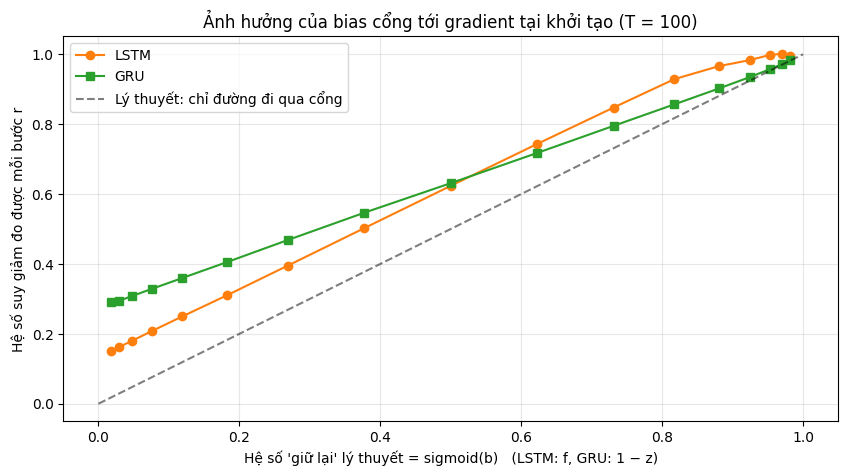

In [ ]:
# Cell 14 — Quét bias liên tục: hệ số giữ lý thuyết vs hệ số suy giảm đo được
T_SWEEP = 100
biases = np.linspace(-4, 4, 17)
sig = lambda x: 1 / (1 + np.exp(-x))

plt.figure(figsize=(10, 5))
for name, marker in [('LSTM', 'o-'), ('GRU', 's-')]:
    rs = [decay_factor_from_curves(measure_init_gradients(name, T_SWEEP, gate_init=float(b), n_seeds=5)[1],
                                   T_SWEEP)[0] for b in biases]
    plt.plot(sig(biases), rs, marker, label=name, color=colors[name])
plt.plot([0, 1], [0, 1], 'k--', alpha=0.5, label='Lý thuyết: chỉ đường đi qua cổng')
plt.xlabel("Hệ số 'giữ lại' lý thuyết = sigmoid(b)   (LSTM: f, GRU: 1 − z)")
plt.ylabel("Hệ số suy giảm đo được mỗi bước r")
plt.title(f"Ảnh hưởng của bias cổng tới gradient tại khởi tạo (T = {T_SWEEP})")
plt.legend(); plt.grid(alpha=0.3)
plt.show()